# Maps of England

## Code setup

In [1]:
import os
import geopandas
import numpy as np
import pandas as pd

# Plotting:
import contextily as ctx  # map tiles
import matplotlib.pyplot as plt

In [2]:
dir_data = 'data'
dir_output = 'output'
dir_images = 'images'
# Scenario results:
file_scen_params = 'scenario_parameters.csv'
file_base_geo = 'results_geo_outcomes_base.csv'
file_base_results = 'results_full_base.csv'
file_taunworc_geo = 'results_geo_outcomes_taunworc.csv'
file_taunworc_results = 'results_full_taunworc.csv'
# Geometry:
file_england_lsoa = 'Lower_layer_super_output_areas_(E+W)_2011_Boundaries_(Generalised_Clipped)_V2.zip'
file_uk_outlines = 'Countries_(December_2022)_GB_BFC.zip'
# Reference:
file_hospitals = 'stroke_hospitals_2025.csv'

## Load data

### Scenario parameters

So we can see which units were changed.

In [3]:
p = os.path.join(dir_output, file_scen_params)

# Use converters to turn units column from strings to lists.
# Assumes that no postcodes contain spaces!
converters = {
    'new_mt_units': lambda x: (
        x.replace("'", '').replace(',', '')[1:-1].split()),
}
df_scen = pd.read_csv(p, converters=converters)

units_changed_base = df_scen.loc[
    df_scen['scenario_name'] == 'base', 'new_mt_units'].values[0]
units_changed_taunworc = df_scen.loc[
    df_scen['scenario_name'] == 'taunworc', 'new_mt_units'].values[0]

In [4]:
print(units_changed_base)
print(units_changed_taunworc)

[]
['TA15DA', 'WR51DD']


### Scenario results

Only load in these columns that are necessary for the maps:

In [7]:
cols_geo = [
    'LSOA',
    'area_lower',
    'nearest_ivt_time_no_bias',
    'drip_ship_mt_travel_time',
]
cols_results = [
    'LSOA',
    'drip_ship_mrs_0-2_improvement_over_no_treatment',
    'lvo_drip_ship_ivt_mt_mrs_0-2_improvement_over_no_treatment',
    'drip_ship_mrs_0-2_improvement_over_no_treatment_transferloss0!6',
    'lvo_drip_ship_ivt_mt_mrs_0-2_improvement_over_no_treatment_transferloss0!6'
]

In [9]:
p = os.path.join(dir_output, file_base_geo)
p2 = os.path.join(dir_output, file_base_results)
df_base = pd.concat(
    (pd.read_csv(p, index_col='LSOA', usecols=cols_geo),
     pd.read_csv(p2, index_col='LSOA', usecols=cols_results)),
    axis='columns'
)

In [10]:
p = os.path.join(dir_output, file_taunworc_geo)
p2 = os.path.join(dir_output, file_taunworc_results)
df_taunworc = pd.concat(
    (pd.read_csv(p, index_col='LSOA', usecols=cols_geo),
     pd.read_csv(p2, index_col='LSOA', usecols=cols_results)),
    axis='columns'
)

In [11]:
display(df_base.head(5))

,nearest_ivt_time_no_bias,area_lower,drip_ship_mt_travel_time,drip_ship_mrs_0-2_improvement_over_no_treatment,lvo_drip_ship_ivt_mt_mrs_0-2_improvement_over_no_treatment,drip_ship_mrs_0-2_improvement_over_no_treatment_transferloss0!6,lvo_drip_ship_ivt_mt_mrs_0-2_improvement_over_no_treatment_transferloss0!6
LSOA,,,,,,,
ADUR001A,11,Adur 001A,10.9,0.134,0.164,0.134,0.164
ADUR001B,12,Adur 001B,11.9,0.133,0.164,0.133,0.164
ADUR001C,11,Adur 001C,95.0,0.117,0.111,0.111,0.091
ADUR001D,12,Adur 001D,11.9,0.133,0.164,0.133,0.164
ADUR001E,10,Adur 001E,94.0,0.118,0.112,0.112,0.091


### Geometry

In [12]:
# Load the England and Wales LSOA shapefile
filename = os.path.join(dir_data, file_england_lsoa)
lsoa_gdf = geopandas.read_file(filename)

# Set or convert to British National Grid (EPSG:27700)
if lsoa_gdf.crs is None:
    lsoa_gdf = lsoa_gdf.set_crs("EPSG:27700")
else:
    lsoa_gdf = lsoa_gdf.to_crs("EPSG:27700")

In [13]:
# Get the England and Wales outline
filename = os.path.join(dir_data, file_uk_outlines)
countries_gdf = geopandas.read_file(filename)

# Set or convert to British National Grid (EPSG:27700)
if countries_gdf.crs is None:
    countries_gdf = countries_gdf.set_crs("EPSG:27700")
else:
    countries_gdf = countries_gdf.to_crs("EPSG:27700")

# Only keep England and Wales outlines:
mask = countries_gdf["CTRY22NM"].isin(["England", "Wales"])
countries_gdf = countries_gdf.loc[mask]
england = countries_gdf.boundary

In [14]:
# Load hospital coordinates from CSV and create a GeoDataFrame
p = os.path.join(dir_data, file_hospitals)
hospitals_df = pd.read_csv(p)

hospitals_gdf = geopandas.GeoDataFrame(
    hospitals_df,
    geometry=geopandas.points_from_xy(
        pd.to_numeric(hospitals_df["long"]),
        pd.to_numeric(hospitals_df["lat"]),
    ),
    crs="EPSG:4326",
).to_crs("EPSG:27700")

# Only keep hospitals in England:
hospitals_gdf = hospitals_gdf.loc[hospitals_gdf["Country"] == "England"]
display(hospitals_gdf.head(3))

,SSNAP name,Postcode,Country,SSNAP Region,Easting,Northing,long,lat,Hospital_City,LSOA11CD,Use_IVT,Use_MT,geometry
0,John Radcliffe Hospital,OX39DU,England,"Buckinghamshire, Oxford and Berkshire",453940,207531,-1.219806,51.763871,Oxford,E01028534,1,1,POINT (453940.001 207531)
1,Royal Berkshire Hospital,RG15AN,England,"Buckinghamshire, Oxford and Berkshire",472411,172962,-0.959330,51.451022,Reading,E01016414,1,0,POINT (472411.001 172961.999)
2,Wycombe General Hospital,HP112TT,England,"Buckinghamshire, Oxford and Berkshire",486386,192694,-0.753428,51.626442,High Wycombe,E01017839,1,0,POINT (486386.001 192694)
3,Countess of Chester Hospital,CH21UL,England,Cheshire and Mersey,340130,368347,-2.897884,53.208800,Chester,E01018374,1,0,POINT (340130.001 368347)
4,Southport and Formby District General,PR86PN,England,Cheshire and Mersey,335417,415683,-2.978159,53.633667,Southport,E01006999,0,0,POINT (335417.001 415683)


## Combine geometry and scenario results

Gather all LSOA scenario results:

In [15]:
rename_dict = dict([(c, f'{c}_taunworc') for c in df_taunworc.columns])
results = pd.concat((df_base, df_taunworc.rename(columns=rename_dict)),
                    axis='columns')

Combine LSOA scenarios with geometry:

In [16]:
# Merge the results with the LSOA shapefile
data = lsoa_gdf.merge(results, left_on='LSOA11NM', right_on='area_lower', how='right')

Hospital services:

In [17]:
# Set up a new column for modifiable MT units by scenario:
hospitals_gdf['use_mt_base'] = hospitals_gdf['Use_MT'].copy()
m = hospitals_gdf['Postcode'].isin(units_changed_base)
hospitals_gdf.loc[m, 'use_mt_base'] = 1

hospitals_gdf['use_mt_taunworc'] = hospitals_gdf['Use_MT'].copy()
m = hospitals_gdf['Postcode'].isin(units_changed_taunworc)
hospitals_gdf.loc[m, 'use_mt_taunworc'] = 1

## Plot setup

Main plotting function:

In [18]:
def plot_maps(
        data,
        england,
        hospitals_gdf,
        map_data,
        column_mt_units,
        savename='',
        show=True
    ):
    fig, axs = plt.subplots(1, len(map_data), figsize=(15, 6))
    
    i = 0
    for map_label, map_dict in map_data.items():
        ax = axs[i]

        # Set up LSOA values and colour limits:
        values = pd.to_numeric(data[map_dict['column']], errors='coerce').astype(float)
        # Use a temporary numeric column; GeoPandas handles the color mapping.
        data['_plot_value'] = values
    
        valid_values = values.where(np.isfinite(values))
        vmin, vmax = valid_values.min(), valid_values.max()
        if vmin == vmax:
            vmax = vmin + 1

        # Plot LSOA:
        data.plot(
            column='_plot_value',
            ax=ax,
            cmap=plt.get_cmap(map_dict['cmap']),
            vmin=vmin,
            vmax=vmax,
            missing_kwds={'color': 'lightgrey'},
            antialiased=False,
            linewidth=0,
            legend=True,
            legend_kwds=dict(
                shrink=0.5,      # shrink the colorbar to 50% of its original size
                pad=0.01,        # gap between map and colorbar (default 0.05)
                fraction=0.05,   # width of colorbar relative to the axes
                label=map_dict['label'],
            ),
        )

        # Country borders:
        england.plot(ax=ax, edgecolor='k', facecolor='none', linewidth=1)

        # Stroke units:
        ivt_mask = pd.to_numeric(
            hospitals_gdf['Use_IVT'], errors='coerce').eq(1)
        mt_mask = pd.to_numeric(
            hospitals_gdf[column_mt_units], errors='coerce').eq(1)
    
        hospitals_gdf.loc[ivt_mask].plot(
            ax=ax, edgecolor='k', facecolor='w', markersize=15, marker='o',
            zorder=99
        )
        hospitals_gdf.loc[mt_mask].plot(
            ax=ax, edgecolor='k', facecolor='w', markersize=100, marker='*',
            zorder=99
        )

        # Axis setup:
        ax.set_title(map_dict['label'])#, fontsize=16)
        ax.apply_aspect()
        ax.set_axis_off()
        i += 1

    if len(savename) > 0:
        plt.savefig(savename, dpi=300, bbox_inches='tight')
    else:
        pass
    if show:
        plt.show()
    else:
        plt.close()

Setup.

Which maps use which column of data?

In [24]:
map_data_all_patients_base = {
    'ivt': {
        'column': 'nearest_ivt_time_no_bias',
        'cmap': 'afmhot_r',
        'label': 'Time to IVT unit (minutes)',
    },
    'mt': {
        'column': 'drip_ship_mt_travel_time',
        'cmap': 'gist_heat_r',
        'label': 'Time to MT unit\n(minutes, including transfer time)',
    },
    'improvement': {
        'column': 'drip_ship_mrs_0-2_improvement_over_no_treatment',
        'cmap': 'inferno',
        'label': 'Additional probability of mRS 0-2\nover untreated',
    },
}

# For LVO, keep everything the same except the data column and label:
map_data_lvo_base = dict()
for k, d in map_data_all_patients_base.items():
    map_data_lvo_base[k] = dict(d.items())
map_data_lvo_base['improvement']['column'] = (
    'lvo_drip_ship_ivt_mt_mrs_0-2_improvement_over_no_treatment')
map_data_lvo_base['improvement']['label'] = (
    'Additional probability of mRS 0-2\nover untreated (for LVO patients)')

# For lossy drip-and-ship, keep everything the same except for
# data column and label.
def copy_dict_and_append_str_to_imp_cols(old_dict, s):
    new_dict = dict()
    for k, d in old_dict.items():
        new_dict[k] = dict(d.items())
        if k == 'improvement':
            new_dict[k]['column'] = d['column'] + s
    return new_dict

map_data_lossy_all_patients_base = copy_dict_and_append_str_to_imp_cols(
    map_data_all_patients_base, '_transferloss0!6')
map_data_lossy_lvo_base = copy_dict_and_append_str_to_imp_cols(
    map_data_lvo_base, '_transferloss0!6')


# Copies for the Taunton and Worcester scenario:
def copy_dict_and_add_str_to_cols(old_dict, s):
    new_dict = dict()
    for k, d in old_dict.items():
        new_dict[k] = dict(d.items())
        new_dict[k]['column'] = d['column'] + s
    return new_dict

map_data_all_patients_taunworc = copy_dict_and_add_str_to_cols(
    map_data_all_patients_base, '_taunworc')
map_data_lvo_taunworc = copy_dict_and_add_str_to_cols(
    map_data_lvo_base, '_taunworc')
map_data_lossy_all_patients_taunworc = copy_dict_and_add_str_to_cols(
    map_data_lossy_all_patients_base, '_taunworc')
map_data_lossy_lvo_taunworc = copy_dict_and_add_str_to_cols(
    map_data_lossy_lvo_base, '_taunworc')

## Plots

Make the plots:

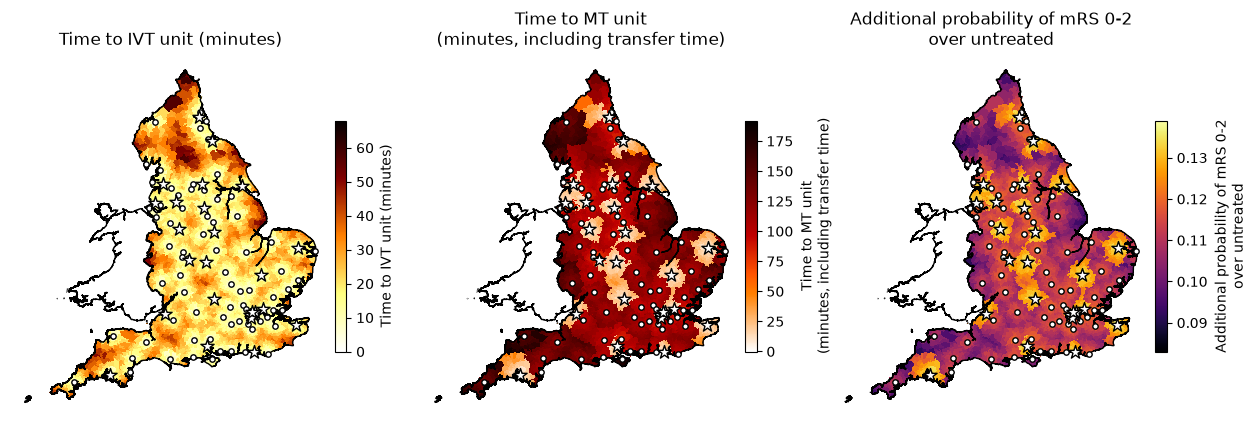

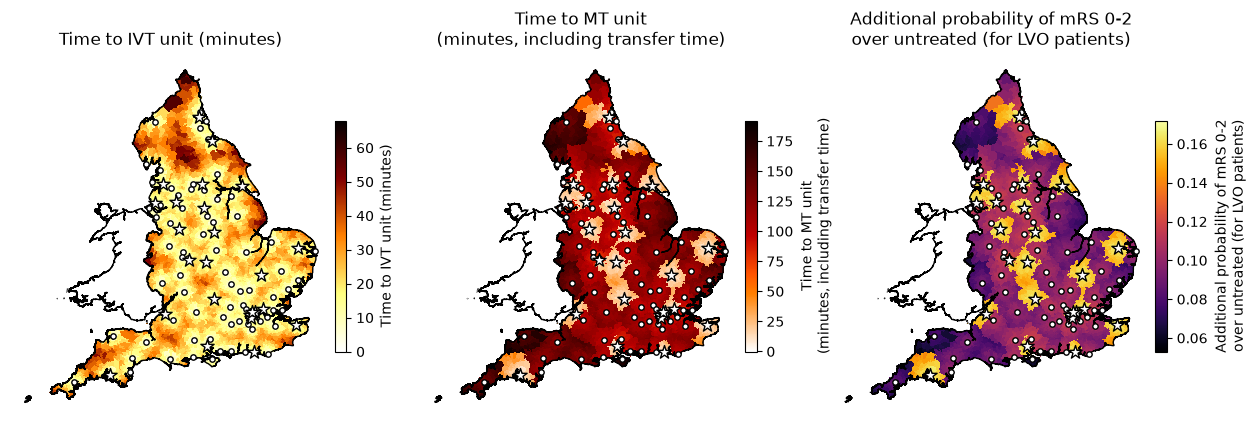

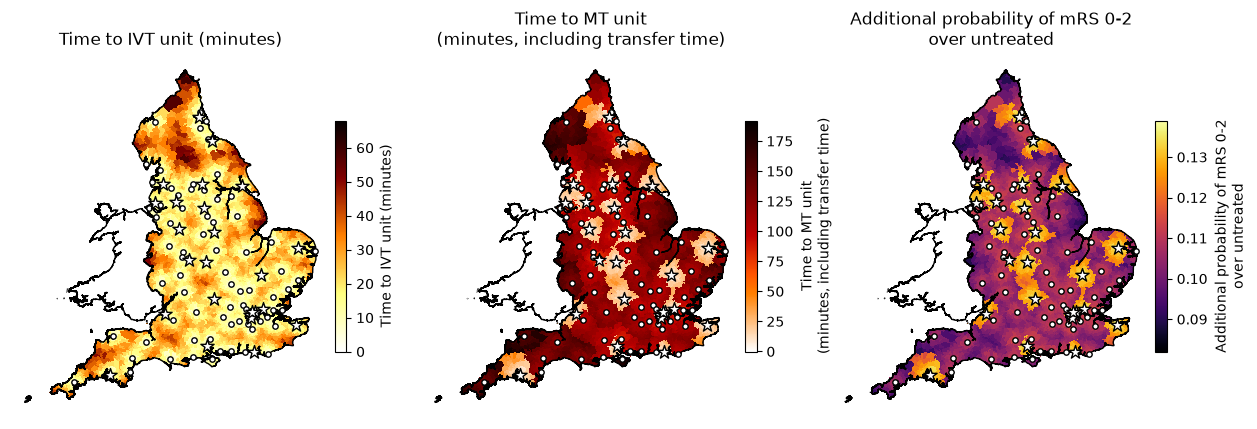

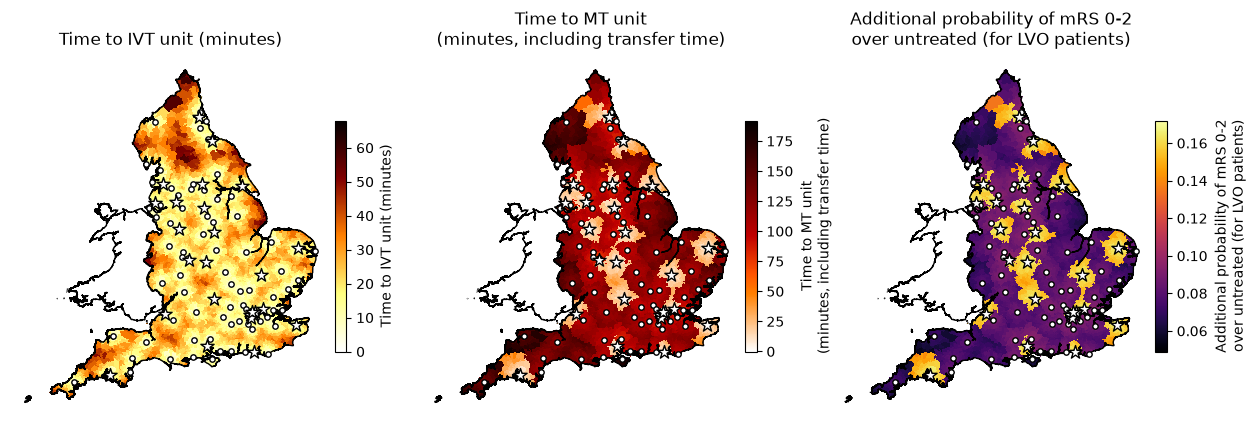

In [26]:
scenario_name = 'base'

column_mt_units = f'use_mt_{scenario_name}'

savename = os.path.join(
    dir_images, f'map_three_in_one_{scenario_name}.png')
savename_lvo = os.path.join(
    dir_images, f'map_three_in_one_{scenario_name}_lvo.png')
savename_lossy = os.path.join(
    dir_images, f'map_three_in_one_lossydripship_{scenario_name}.png')
savename_lossy_lvo = os.path.join(
    dir_images, f'map_three_in_one_lossydripship_{scenario_name}_lvo.png')

plot_maps(data, england, hospitals_gdf,
          map_data_all_patients_base, column_mt_units,
          savename=savename, show=True)
plot_maps(data, england, hospitals_gdf,
          map_data_lvo_base, column_mt_units,
          savename=savename_lvo, show=True)
plot_maps(data, england, hospitals_gdf,
          map_data_lossy_all_patients_base, column_mt_units,
          savename=savename_lossy, show=True)
plot_maps(data, england, hospitals_gdf,
          map_data_lossy_lvo_base, column_mt_units,
          savename=savename_lossy_lvo, show=True)


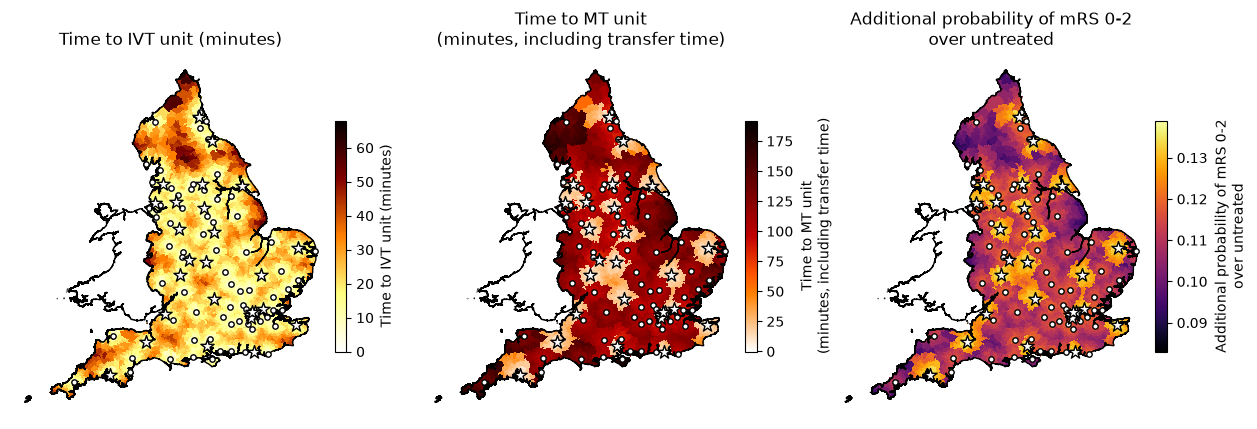

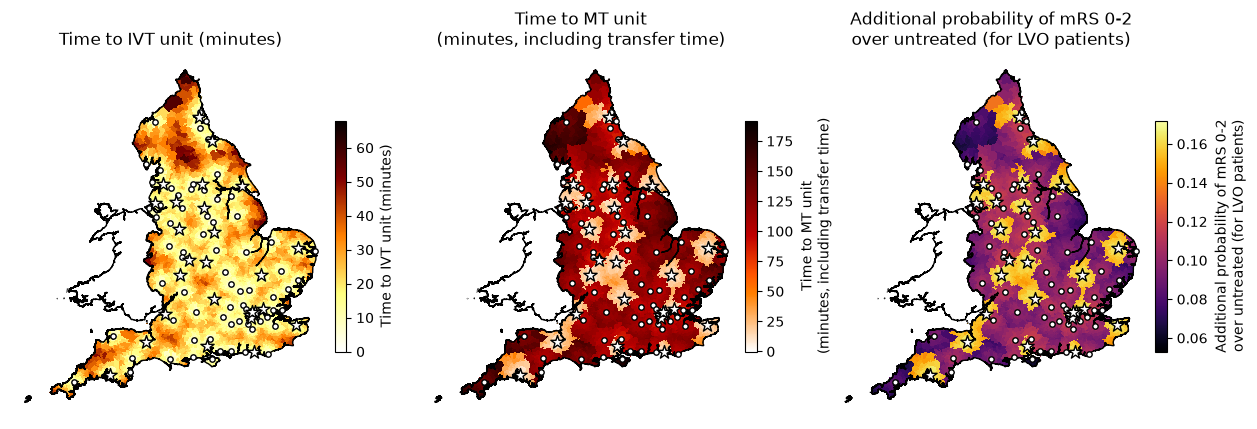

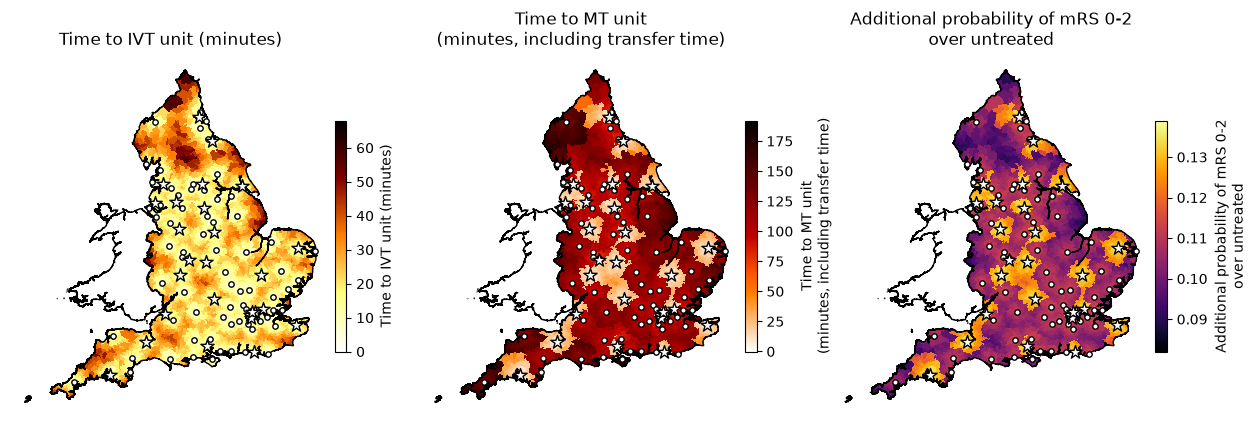

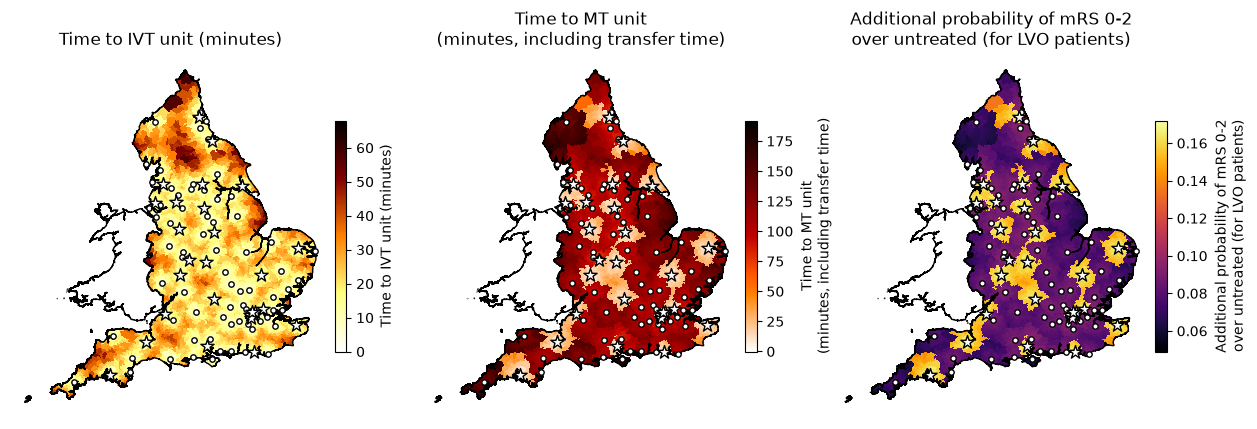

In [27]:
scenario_name = 'taunworc'

column_mt_units = f'use_mt_{scenario_name}'

savename = os.path.join(
    dir_images, f'map_three_in_one_{scenario_name}.png')
savename_lvo = os.path.join(
    dir_images, f'map_three_in_one_{scenario_name}_lvo.png')
savename_lossy = os.path.join(
    dir_images, f'map_three_in_one_lossydripship_{scenario_name}.png')
savename_lossy_lvo = os.path.join(
    dir_images, f'map_three_in_one_lossydripship_{scenario_name}_lvo.png')

plot_maps(data, england, hospitals_gdf,
          map_data_all_patients_taunworc, column_mt_units,
          savename=savename, show=True)
plot_maps(data, england, hospitals_gdf,
          map_data_lvo_taunworc, column_mt_units,
          savename=savename_lvo, show=True)
plot_maps(data, england, hospitals_gdf,
          map_data_lossy_all_patients_taunworc, column_mt_units,
          savename=savename_lossy, show=True)
plot_maps(data, england, hospitals_gdf,
          map_data_lossy_lvo_taunworc, column_mt_units,
          savename=savename_lossy_lvo, show=True)
